# Predictive Maintenance for Transportation Fleets

**Student name:** Sahan Gamage  
**Assignment:** Advanced Neural Network Models

This repository contains my notebook and supporting files for a predictive maintenance assignment. Part A analyses MetroPT-3 train sensor readings using PCA, an autoencoder, and a Self-Organising Map (SOM). Part B uses an LSTM model to predict Remaining Useful Life (RUL) with the NASA C-MAPSS FD001 dataset.

# MetroPT-3 Train Sensor Data Analysis

This project analyses sensor readings from the MetroPT-3 dataset.

First, the dataset is loaded and checked. Then the sensor data is prepared for analysis using PCA, a linear autoencoder and a Self-Organising Map.



In [1]:
# Cell 1 — Import libraries and load the CSV from Google Drive

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")

csv_path = Path("/content/drive/MyDrive/MetroPT3(AirCompressor).csv")

if not csv_path.is_file():
    raise FileNotFoundError(f"CSV file not found at: {csv_path}")

raw = pd.read_csv(csv_path)

print(f"Rows: {len(raw):,}")
print(f"CSV columns: {raw.shape[1]}")
display(raw.head())

Mounted at /content/drive
Rows: 1,516,948
CSV columns: 17


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


## Check the CSV structure

Before analysing the sensor readings, check the column names, data types, missing values and number of unique values. Also identify any extra columns in the CSV.

In [2]:
# Cell 2 — Check the CSV structure, data types and missing values

analog_cols = [
    "TP2", "TP3", "H1", "DV_pressure", "Reservoirs",
    "Oil_temperature", "Motor_current"
]

digital_cols = [
    "COMP", "DV_eletric", "Towers", "MPG", "LPS",
    "Pressure_switch", "Oil_level", "Caudal_impulses"
]

sensor_cols = analog_cols + digital_cols
required_cols = ["timestamp", *sensor_cols]

missing_cols = [col for col in required_cols if col not in raw.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

column_check = pd.DataFrame({
    "Data type": raw.dtypes.astype(str),
    "Missing values": raw.isna().sum(),
    "Unique values": raw.nunique()
})
display(column_check)

print("Extra CSV columns:", [col for col in raw.columns if col not in required_cols])

,Data type,Missing values,Unique values
Unnamed: 0,int64,0,1516948
timestamp,object,0,1516948
TP2,float64,0,5257
TP3,float64,0,3683
H1,float64,0,2665
DV_pressure,float64,0,2257
Reservoirs,float64,0,3682
Oil_temperature,float64,0,2462
Motor_current,float64,0,1809
COMP,float64,0,2


Extra CSV columns: ['Unnamed: 0']


## Check invalid values and clean the sensor readings

The CSV contains an extra row-index column, so keep only the timestamp and required sensor columns. Convert the timestamp and sensor values to the correct data types, then check for invalid values, duplicate rows, repeated timestamps and invalid digital readings.

In [3]:
# Cell 3 — Check invalid values and clean the original readings

# Select the timestamp and sensors to exclude the extra CSV row index.
df = raw[required_cols].copy()

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df[sensor_cols] = df[sensor_cols].apply(pd.to_numeric, errors="coerce")

infinite_counts = df[sensor_cols].isin([np.inf, -np.inf]).sum()
df[sensor_cols] = df[sensor_cols].replace([np.inf, -np.inf], np.nan)

quality_check = pd.DataFrame({
    "Missing or invalid after conversion": df.isna().sum(),
    "Infinite values detected": infinite_counts.reindex(required_cols, fill_value=0)
})
display(quality_check)

print(f"Exact duplicate rows: {df.duplicated().sum():,}")

valid_timestamps = df["timestamp"].dropna()
print(f"Repeated timestamps: {valid_timestamps.duplicated().sum():,}")
print(f"Timestamps already sorted: {valid_timestamps.is_monotonic_increasing}")

df = df.dropna(subset=required_cols).drop_duplicates()

if df["timestamp"].duplicated().any():
    raise ValueError("Some timestamps contain conflicting sensor readings.")

invalid_digital = (~df[digital_cols].isin([0, 1])).sum()
display(invalid_digital.rename("Values outside 0 and 1").to_frame())

if invalid_digital.any():
    raise ValueError("Review the digital sensor values before continuing.")

# Keep one row per original reading. Use the timestamp as the index.
metro = df.sort_values("timestamp").set_index("timestamp")

print(f"Rows after cleaning: {len(metro):,}")
print(f"Rows removed: {len(raw) - len(metro):,}")
print(f"Sensor columns: {metro.shape[1]}")
display(metro.head())

,Missing or invalid after conversion,Infinite values detected
timestamp,0,0
TP2,0,0
TP3,0,0
H1,0,0
DV_pressure,0,0
Reservoirs,0,0
Oil_temperature,0,0
Motor_current,0,0
COMP,0,0
DV_eletric,0,0


Exact duplicate rows: 0
Repeated timestamps: 0
Timestamps already sorted: True


,Values outside 0 and 1
COMP,0
DV_eletric,0
Towers,0
MPG,0
LPS,0
Pressure_switch,0
Oil_level,0
Caudal_impulses,0


Rows after cleaning: 1,516,948
Rows removed: 0
Sensor columns: 15


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


## Check timestamp coverage and sensor variation

Check the time range covered by the readings, identify gaps longer than one minute, and find sensors that have no variation across the cleaned dataset.

In [4]:
# Cell 4 — Check timestamp coverage, gaps and constant sensors

time_gaps = metro.index.to_series().diff().dropna()
long_gaps = time_gaps[time_gaps > pd.Timedelta(minutes=1)]

print(f"First reading: {metro.index.min()}")
print(f"Last reading:  {metro.index.max()}")
print(f"Gaps longer than one minute: {len(long_gaps):,}")

display(
    time_gaps.value_counts().head(5)
    .rename_axis("Interval between consecutive readings")
    .rename("Count")
    .to_frame()
)

print("Five longest gaps")
display(
    time_gaps.nlargest(5)
    .rename_axis("Timestamp after the gap")
    .rename("Gap duration")
    .to_frame()
)

unique_counts = metro[sensor_cols].nunique()
constant_cols = unique_counts[unique_counts <= 1].index.tolist()
print("Constant sensors across the full dataset:", constant_cols)

First reading: 2020-02-01 00:00:00
Last reading:  2020-09-01 03:59:50
Gaps longer than one minute: 331


,Count
Interval between consecutive readings,
0 days 00:00:10,1337521
0 days 00:00:09,128277
0 days 00:00:12,38321
0 days 00:00:13,7988
0 days 00:00:11,4471


Five longest gaps


,Gap duration
Timestamp after the gap,
2020-04-27 01:12:49,2 days 00:01:58
2020-06-28 23:07:43,1 days 12:14:36
2020-03-01 04:00:09,1 days 04:03:01
2020-08-05 08:23:01,1 days 00:40:33
2020-05-25 01:14:14,1 days 00:34:51


Constant sensors across the full dataset: []


## Explore sensor distributions

Summarise the analogue sensor readings and calculate how often each digital sensor is in state 0 or state 1. Use histograms to visualise the distributions of the analogue readings.

Summary statistics for analogue sensors


,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.368,3.251,-0.032,-0.014,-0.012,-0.010,10.676
TP3,1516948.0,8.985,0.639,0.730,8.492,8.960,9.492,10.302
H1,1516948.0,7.568,3.333,-0.036,8.254,8.784,9.374,10.288
DV_pressure,1516948.0,0.056,0.382,-0.032,-0.022,-0.020,-0.018,9.844
Reservoirs,1516948.0,8.985,0.638,0.712,8.494,8.960,9.492,10.300
Oil_temperature,1516948.0,62.644,6.516,15.400,57.775,62.700,67.250,89.050
Motor_current,1516948.0,2.050,2.302,0.020,0.040,0.045,3.808,9.295


,Readings in state 0 (%),Readings in state 1 (%)
COMP,16.30,83.70
DV_eletric,83.94,16.06
Towers,8.02,91.98
MPG,16.73,83.27
LPS,99.66,0.34
Pressure_switch,0.86,99.14
Oil_level,9.58,90.42
Caudal_impulses,6.29,93.71


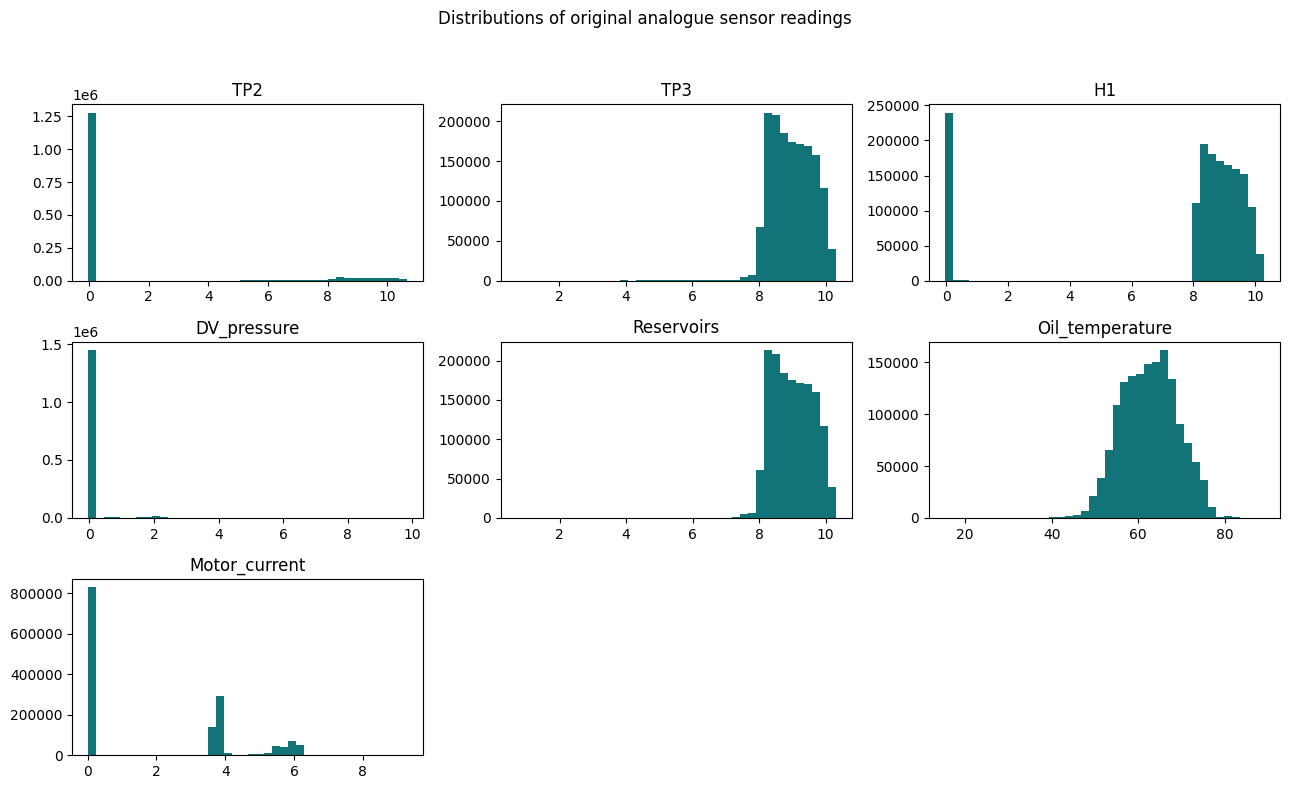

In [5]:
# Cell 5 — EDA with summary statistics and histograms

print("Summary statistics for analogue sensors")
display(metro[analog_cols].describe().T.round(3))

digital_summary = pd.DataFrame({
    "Readings in state 0 (%)": metro[digital_cols].eq(0).mean().mul(100),
    "Readings in state 1 (%)": metro[digital_cols].eq(1).mean().mul(100)
})
display(digital_summary.round(2))

axes = metro[analog_cols].hist(
    bins=40,
    figsize=(13, 8),
    color="#127379",
    grid=False
)

fig = axes.flat[0].get_figure()
fig.suptitle("Distributions of original analogue sensor readings")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Explore sensor relationships and daily changes

Compare the sensor readings using pairwise correlations. Then examine how selected sensors change over one day by plotting their five-minute average values.

Ten strongest sensor relationships


,Sensor 1,Sensor 2,Correlation
16,TP3,Reservoirs,1.000
79,COMP,MPG,0.985
85,DV_eletric,MPG,-0.976
31,H1,COMP,0.971
1,TP2,H1,-0.961
77,COMP,DV_eletric,-0.959
32,H1,DV_eletric,-0.959
6,TP2,COMP,-0.956
34,H1,MPG,0.954
7,TP2,DV_eletric,0.947


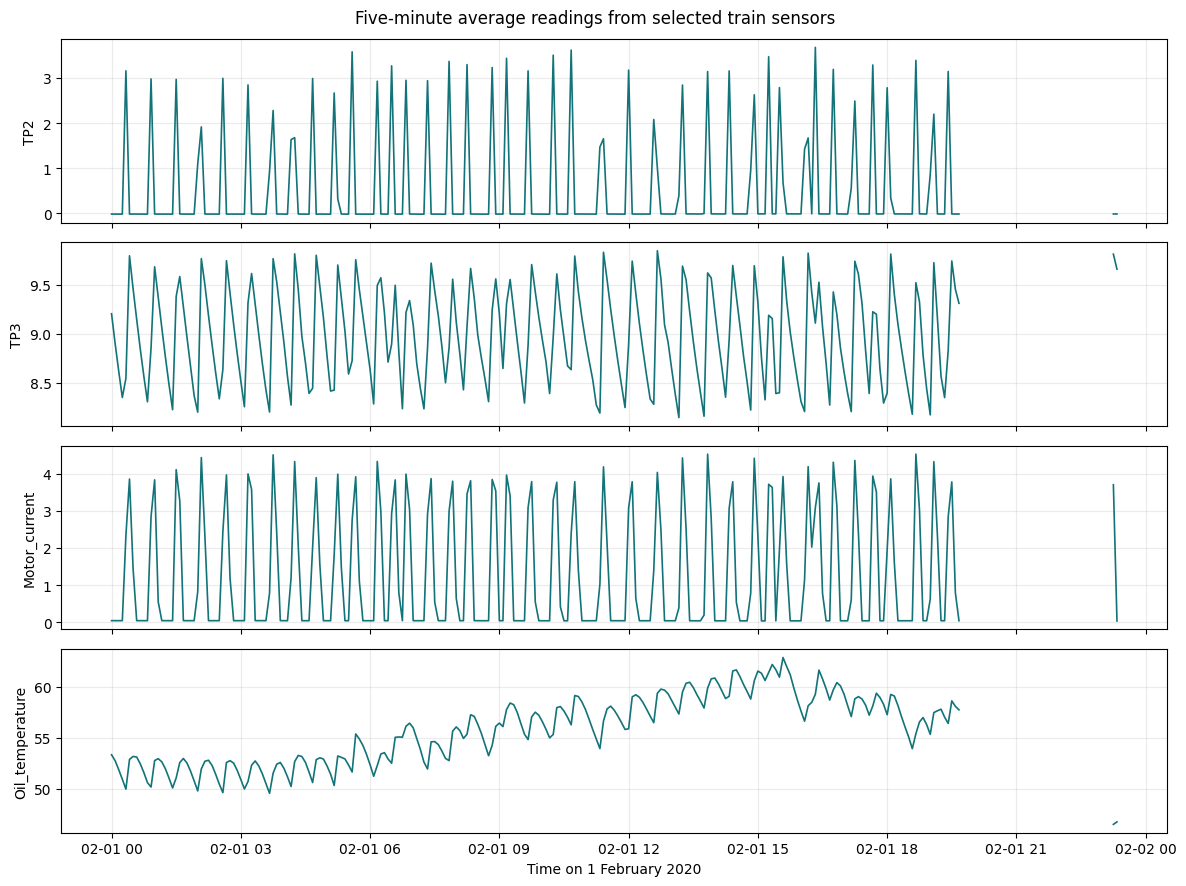

In [6]:
# Cell 6 — Rank sensor correlations and plot daily sensor patterns

correlation_matrix = metro[sensor_cols].corr()

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

correlation_pairs = (
    upper_triangle
    .stack()
    .rename_axis(["Sensor 1", "Sensor 2"])
    .reset_index(name="Correlation")
)

correlation_pairs["Absolute correlation"] = (
    correlation_pairs["Correlation"].abs()
)

top_pairs = correlation_pairs.sort_values(
    "Absolute correlation",
    ascending=False
).head(10)

print("Ten strongest sensor relationships")
display(top_pairs.drop(columns="Absolute correlation").round(3))

sensors_to_plot = [
    "TP2", "TP3", "Motor_current", "Oil_temperature"
]

# Average the readings into five-minute intervals for a clearer daily view.
daily_readings = (
    metro.loc["2020-02-01", sensors_to_plot]
    .resample("5min")
    .mean()
)

fig, axes = plt.subplots(
    len(sensors_to_plot),
    1,
    figsize=(12, 9),
    sharex=True
)

for axis, sensor in zip(axes, sensors_to_plot):
    axis.plot(
        daily_readings.index,
        daily_readings[sensor],
        color="#127379",
        linewidth=1.2
    )
    axis.set_ylabel(sensor)
    axis.grid(alpha=0.25)

axes[-1].set_xlabel("Time on 1 February 2020")
fig.suptitle("Five-minute average readings from selected train sensors")
fig.tight_layout()
plt.show()

## Prepare sensor data for PCA

Split the readings by time: February for training, March for validation, and April onwards for evaluation. Standardise the analogue sensors using the training period. Keep digital sensor states as 0 and 1 so that a rare state, such as LPS, is not magnified by dividing by a very small standard deviation.

In [7]:
# Cell 7 — Split the readings and scale analogue sensors

from sklearn.preprocessing import StandardScaler

march_boundary = pd.Timestamp("2020-03-01")
april_boundary = pd.Timestamp("2020-04-01")

training_rows = metro.loc[metro.index < march_boundary]
validation_rows = metro.loc[
    (metro.index >= march_boundary) & (metro.index < april_boundary)
]
evaluation_rows = metro.loc[metro.index >= april_boundary]

analogue_inputs = [
    sensor for sensor in analog_cols
    if training_rows[sensor].nunique() > 1
]

digital_inputs = [
    sensor for sensor in digital_cols
    if training_rows[sensor].nunique() > 1
]

active_sensors = analogue_inputs + digital_inputs

analogue_scaler = StandardScaler()
analogue_scaler.fit(training_rows[analogue_inputs])


def prepare_sensor_matrix(frame):
    scaled_analogue = analogue_scaler.transform(
        frame[analogue_inputs]
    ).astype("float32")

    digital_states = frame[digital_inputs].to_numpy(dtype="float32")

    return np.concatenate(
        [scaled_analogue, digital_states],
        axis=1
    )


training_values = prepare_sensor_matrix(training_rows)
validation_values = prepare_sensor_matrix(validation_rows)
evaluation_values = prepare_sensor_matrix(evaluation_rows)

print(f"Training matrix: {training_values.shape}")
print(f"Validation matrix: {validation_values.shape}")
print(f"Evaluation matrix: {evaluation_values.shape}")
print("Analogue sensors scaled:", analogue_inputs)
print("Digital sensors kept as 0/1:", digital_inputs)
print(
    "LPS values in training matrix:",
    np.unique(training_values[:, active_sensors.index("LPS")])
)

Training matrix: (214850, 13)
Validation matrix: (230448, 13)
Evaluation matrix: (1071650, 13)
Analogue sensors scaled: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
Digital sensors kept as 0/1: ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch']
LPS values in training matrix: [0. 1.]


## Reduce the sensor data with PCA

Fit PCA on the prepared training matrix and retain two components. Apply the fitted model to the validation and evaluation matrices, then calculate the proportion of training variation represented by the two components.

In [8]:
# Cell 8 — Fit PCA using the revised sensor matrices

from sklearn.decomposition import PCA

pca_model = PCA(n_components=2)

training_projection = pca_model.fit_transform(training_values)
validation_projection = pca_model.transform(validation_values)
evaluation_projection = pca_model.transform(evaluation_values)

variance_percent = pca_model.explained_variance_ratio_ * 100

pca_summary = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Training variance explained (%)": variance_percent
})

print("Input sensor count:", training_values.shape[1])
print("Reduced training shape:", training_projection.shape)
print(f"Variance retained by two components: {variance_percent.sum():.2f}%")
display(pca_summary.round(2))

evaluation_pca = pd.DataFrame(
    evaluation_projection,
    index=evaluation_rows.index,
    columns=["PC1", "PC2"]
)
display(evaluation_pca.head())


Input sensor count: 13
Reduced training shape: (214850, 2)
Variance retained by two components: 71.00%


,Component,Training variance explained (%)
0,PC1,38.66
1,PC2,32.34


,PC1,PC2
timestamp,,
2020-04-01 00:00:09,-0.949637,-0.095566
2020-04-01 00:00:18,-0.973036,-0.124715
2020-04-01 00:00:28,-1.000221,-0.163119
2020-04-01 00:00:38,-1.024035,-0.196681
2020-04-01 00:00:48,-1.054432,-0.236038


## Visualise the updated PCA projection

Plot a reproducible sample of the evaluation readings using PC1 and PC2. Colour the points by month to explore whether the sensor patterns change over time.

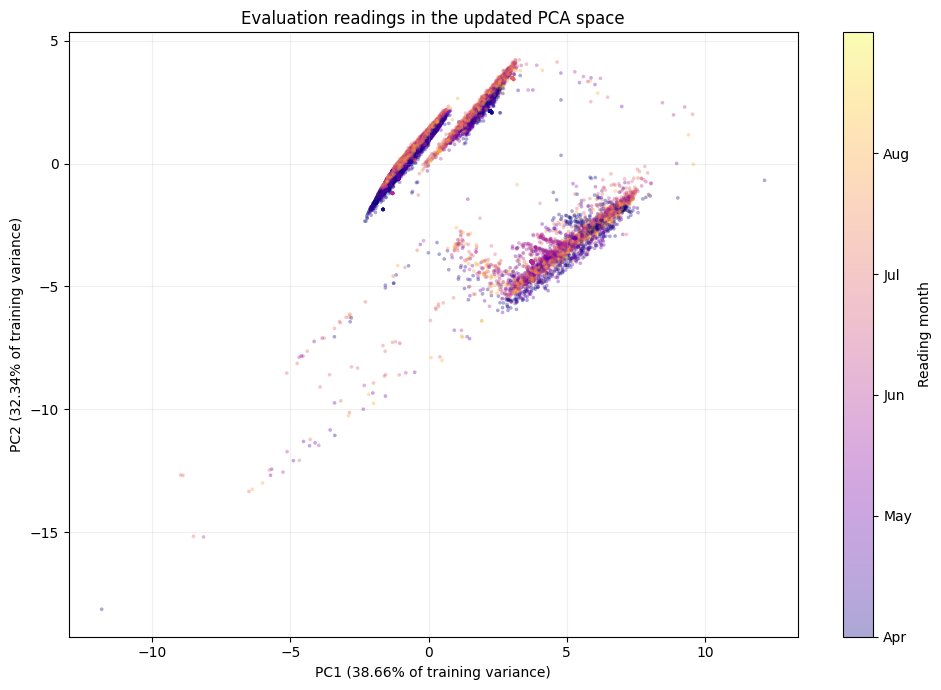

In [9]:
# Cell 9 — Visualise the updated evaluation projection

plot_data = evaluation_pca.copy()
plot_data["Month"] = plot_data.index.month

plot_sample = plot_data.sample(
    n=min(20_000, len(plot_data)),
    random_state=17
)

fig, axis = plt.subplots(figsize=(10, 7))

points = axis.scatter(
    plot_sample["PC1"],
    plot_sample["PC2"],
    c=plot_sample["Month"],
    cmap="plasma",
    s=7,
    alpha=0.35,
    linewidths=0
)

month_bar = fig.colorbar(points, ax=axis)
month_bar.set_ticks([4, 5, 6, 7, 8])
month_bar.set_ticklabels(["Apr", "May", "Jun", "Jul", "Aug"])
month_bar.set_label("Reading month")

axis.set_xlabel(f"PC1 ({variance_percent[0]:.2f}% of training variance)")
axis.set_ylabel(f"PC2 ({variance_percent[1]:.2f}% of training variance)")
axis.set_title("Evaluation readings in the updated PCA space")
axis.grid(alpha=0.2)

fig.tight_layout()
plt.show()

## Train a linear autoencoder

Train a linear autoencoder with two latent values using the revised training matrix. Use the validation readings to choose the model version with the lowest reconstruction error.

In [10]:
# Cell 10 — Train the autoencoder on the revised sensor data

import copy

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(17)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

feature_count = training_values.shape[1]

encoder_layer = nn.Linear(feature_count, 2)
decoder_layer = nn.Linear(2, feature_count)
autoencoder = nn.Sequential(encoder_layer, decoder_layer).to(device)

training_tensor = torch.from_numpy(training_values)
validation_tensor = torch.from_numpy(validation_values).to(device)

training_batches = DataLoader(
    TensorDataset(training_tensor),
    batch_size=8192,
    shuffle=True,
    generator=torch.Generator().manual_seed(17)
)

optimizer = torch.optim.AdamW(autoencoder.parameters(), lr=0.003)
loss_function = nn.MSELoss()

training_history = []
best_validation_error = float("inf")
best_parameters = None
epochs_without_improvement = 0
patience = 4

for epoch in range(1, 26):
    autoencoder.train()
    total_training_error = 0.0

    for (batch,) in training_batches:
        batch = batch.to(device)

        optimizer.zero_grad()
        reconstructed = autoencoder(batch)
        loss = loss_function(reconstructed, batch)
        loss.backward()
        optimizer.step()

        total_training_error += loss.item() * len(batch)

    mean_training_error = total_training_error / len(training_tensor)

    autoencoder.eval()
    with torch.inference_mode():
        validation_reconstruction = autoencoder(validation_tensor)
        validation_error = loss_function(
            validation_reconstruction,
            validation_tensor
        ).item()

    training_history.append({
        "Epoch": epoch,
        "Training MSE": mean_training_error,
        "Validation MSE": validation_error
    })

    if validation_error < best_validation_error:
        best_validation_error = validation_error
        best_parameters = copy.deepcopy(autoencoder.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}: "
        f"training MSE = {mean_training_error:.5f}, "
        f"validation MSE = {validation_error:.5f}"
    )

    if epochs_without_improvement >= patience:
        print("Stopped after validation error stopped improving.")
        break

autoencoder.load_state_dict(best_parameters)
autoencoder.eval()

print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_validation_error:.5f}")

Training device: cpu
Epoch 01: training MSE = 1.31175, validation MSE = 2.34957
Epoch 02: training MSE = 0.98541, validation MSE = 1.97298
Epoch 03: training MSE = 0.75722, validation MSE = 1.71127
Epoch 04: training MSE = 0.59015, validation MSE = 1.52073
Epoch 05: training MSE = 0.49181, validation MSE = 1.37824
Epoch 06: training MSE = 0.43659, validation MSE = 1.27478
Epoch 07: training MSE = 0.40264, validation MSE = 1.19894
Epoch 08: training MSE = 0.37884, validation MSE = 1.13964
Epoch 09: training MSE = 0.36033, validation MSE = 1.09275
Epoch 10: training MSE = 0.34530, validation MSE = 1.05642
Epoch 11: training MSE = 0.33296, validation MSE = 1.02802
Epoch 12: training MSE = 0.32279, validation MSE = 1.00606
Epoch 13: training MSE = 0.31407, validation MSE = 0.98808
Epoch 14: training MSE = 0.30609, validation MSE = 0.97346
Epoch 15: training MSE = 0.29826, validation MSE = 0.96187
Epoch 16: training MSE = 0.29021, validation MSE = 0.95093
Epoch 17: training MSE = 0.28192, v

## Compare PCA and autoencoder reconstruction

Measure the reconstruction error of both methods on the same validation readings. Compare the overall errors and inspect each sensor's error.

In [12]:
# Cell 11 — Compare both methods on the validation readings

with torch.inference_mode():
    autoencoder_reconstruction = (
        autoencoder(validation_tensor)
        .cpu()
        .numpy()
    )

pca_reconstruction = pca_model.inverse_transform(validation_projection)

pca_sensor_error = np.mean(
    np.square(validation_values - pca_reconstruction),
    axis=0
)

autoencoder_sensor_error = np.mean(
    np.square(validation_values - autoencoder_reconstruction),
    axis=0
)

error_comparison = pd.DataFrame(
    {
        "PCA MSE": pca_sensor_error,
        "Autoencoder MSE": autoencoder_sensor_error
    },
    index=active_sensors
)

print(f"Overall PCA validation MSE: {pca_sensor_error.mean():.5f}")
print(
    "Overall autoencoder validation MSE: "
    f"{autoencoder_sensor_error.mean():.5f}"
)

display(
    error_comparison
    .sort_values("Autoencoder MSE", ascending=False)
    .round(5)
)

Overall PCA validation MSE: 0.81302
Overall autoencoder validation MSE: 0.87134


,PCA MSE,Autoencoder MSE
DV_pressure,4.04757,4.04925
Oil_temperature,5.23640,3.42185
TP3,0.34891,0.83939
Reservoirs,0.35148,0.83381
H1,0.14119,0.70678
TP2,0.07688,0.43461
Motor_current,0.30053,0.30221
Pressure_switch,0.00361,0.29248
Towers,0.04423,0.22131
COMP,0.00553,0.13916


## Compare the PCA and autoencoder representations

Map the autoencoder's two-dimensional coordinates onto the PCA coordinate system using training readings. Compare the aligned representations on evaluation readings using component correlations and side-by-side plots.

,Component,Evaluation correlation after alignment
0,PC1,0.9990
1,PC2,0.9442


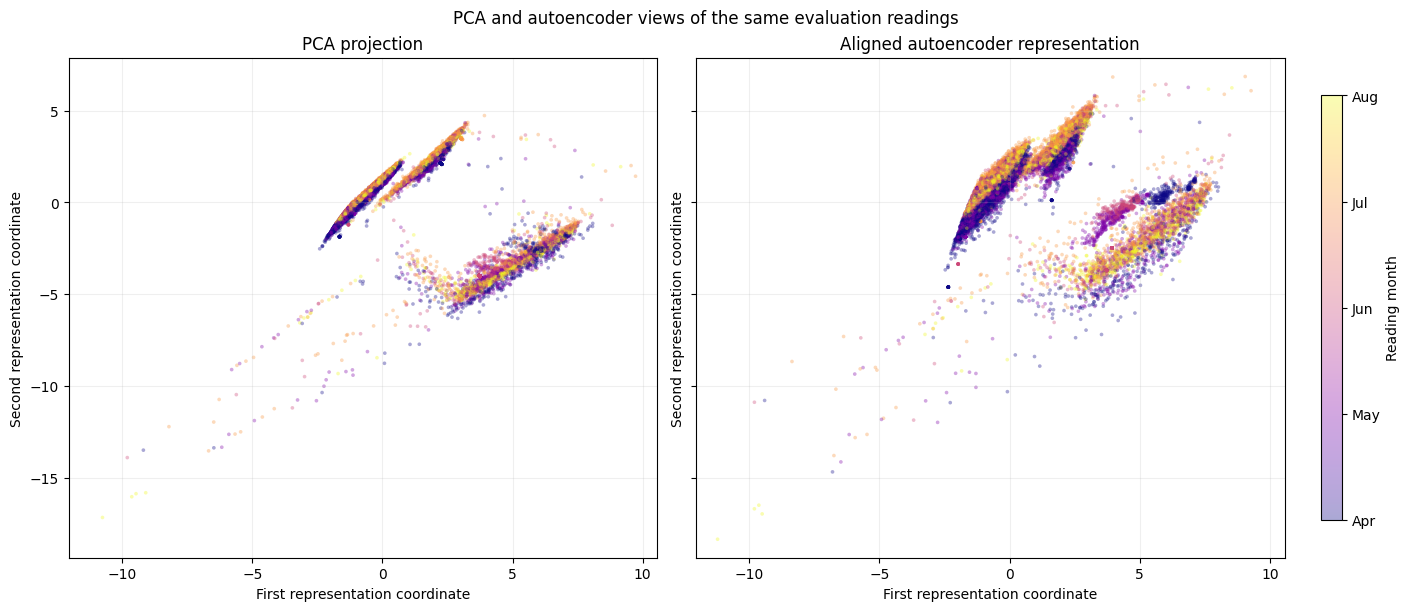

In [13]:
# Cell 12 — Compare the PCA and autoencoder representations

from matplotlib.colors import Normalize

def encode_in_batches(matrix, batch_size=65_536):
    encoded_batches = []

    with torch.inference_mode():
        for start in range(0, len(matrix), batch_size):
            batch = torch.from_numpy(
                matrix[start:start + batch_size]
            ).to(device)

            encoded_batches.append(
                encoder_layer(batch).cpu().numpy()
            )

    return np.concatenate(encoded_batches, axis=0)


# Create autoencoder coordinates for training and evaluation readings.
autoencoder_training_scores = encode_in_batches(training_values)
autoencoder_evaluation_scores = encode_in_batches(evaluation_values)

# Align autoencoder coordinates to PCA coordinates using training data only.
training_design = np.column_stack([
    autoencoder_training_scores,
    np.ones(len(autoencoder_training_scores))
])

alignment_matrix, *_ = np.linalg.lstsq(
    training_design,
    training_projection,
    rcond=None
)

evaluation_design = np.column_stack([
    autoencoder_evaluation_scores,
    np.ones(len(autoencoder_evaluation_scores))
])

aligned_evaluation_scores = evaluation_design @ alignment_matrix

# Compare the aligned coordinates on evaluation readings.
component_correlations = [
    np.corrcoef(
        evaluation_projection[:, component],
        aligned_evaluation_scores[:, component]
    )[0, 1]
    for component in range(2)
]

correlation_table = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Evaluation correlation after alignment": component_correlations
})

display(correlation_table.round(4))

# Use the same sample of readings in both plots.
rng = np.random.default_rng(17)
sample_positions = rng.choice(
    len(evaluation_projection),
    size=min(20_000, len(evaluation_projection)),
    replace=False
)

pca_sample = evaluation_projection[sample_positions]
autoencoder_sample = aligned_evaluation_scores[sample_positions]
sample_months = evaluation_rows.index.month.to_numpy()[sample_positions]

# Use shared axis limits so the plots can be compared fairly.
all_coordinates = np.vstack([
    pca_sample,
    autoencoder_sample
])

x_min, x_max = all_coordinates[:, 0].min(), all_coordinates[:, 0].max()
y_min, y_max = all_coordinates[:, 1].min(), all_coordinates[:, 1].max()

x_padding = (x_max - x_min) * 0.04
y_padding = (y_max - y_min) * 0.04

month_scale = Normalize(vmin=4, vmax=8)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True,
    layout="constrained"
)

for axis, coordinates, title in zip(
    axes,
    [pca_sample, autoencoder_sample],
    ["PCA projection", "Aligned autoencoder representation"]
):
    points = axis.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        c=sample_months,
        cmap="plasma",
        norm=month_scale,
        s=7,
        alpha=0.35,
        linewidths=0
    )

    axis.set_title(title)
    axis.set_xlabel("First representation coordinate")
    axis.set_ylabel("Second representation coordinate")
    axis.set_xlim(x_min - x_padding, x_max + x_padding)
    axis.set_ylim(y_min - y_padding, y_max + y_padding)
    axis.grid(alpha=0.2)

colorbar = fig.colorbar(
    points,
    ax=axes,
    location="right",
    shrink=0.85,
    pad=0.03
)
colorbar.set_ticks([4, 5, 6, 7, 8])
colorbar.set_ticklabels(["Apr", "May", "Jun", "Jul", "Aug"])
colorbar.set_label("Reading month")

fig.suptitle("PCA and autoencoder views of the same evaluation readings")
plt.show()

## Install the SOM library

Install MiniSom, a Python library used to create and train a Self-Organising Map.

In [14]:
%pip install -q minisom

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Train a Self-Organising Map

Train a 10 by 10 Self-Organising Map using the standardised analogue readings and binary digital states. The SOM will group readings with similar sensor patterns into nearby map cells.

In [15]:
# Cell 14 — Train the SOM

from minisom import MiniSom

som_grid_size = 10

som_model = MiniSom(
    x=som_grid_size,
    y=som_grid_size,
    input_len=training_values.shape[1],
    sigma=1.4,
    learning_rate=0.35,
    neighborhood_function="gaussian",
    random_seed=23
)

som_model.random_weights_init(training_values)
som_model.train_random(
    training_values,
    num_iteration=40_000,
    verbose=False
)

print(f"SOM grid: {som_grid_size} × {som_grid_size}")
print(f"Sensor inputs: {training_values.shape[1]}")
print("SOM training completed.")

SOM grid: 10 × 10
Sensor inputs: 13
SOM training completed.


## Visualise SOM patterns in evaluation readings

Map a sample of evaluation readings to their closest SOM cells. Visualise the map distances, the number of readings assigned to each cell, and the month of each sampled reading.

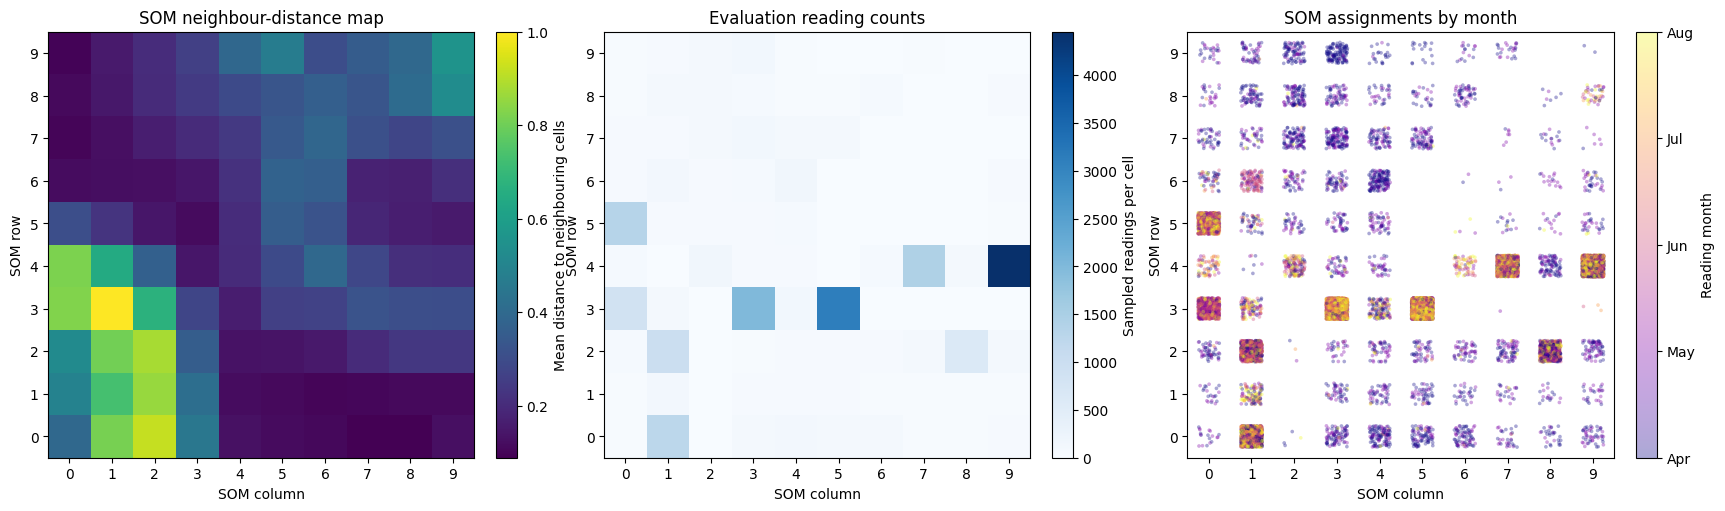

Evaluation readings sampled: 20,000
Occupied SOM cells: 90 out of 100


In [16]:
# Cell 15 — Map evaluation readings and visualise the SOM

sample_rng = np.random.default_rng(23)
som_sample_positions = sample_rng.choice(
    len(evaluation_values),
    size=min(20_000, len(evaluation_values)),
    replace=False
)

som_evaluation_sample = evaluation_values[som_sample_positions]
som_sample_months = (
    evaluation_rows.index.month.to_numpy()[som_sample_positions]
)

som_assignments = np.array([
    som_model.winner(reading)
    for reading in som_evaluation_sample
])

som_hit_counts = np.zeros(
    (som_grid_size, som_grid_size),
    dtype=int
)
np.add.at(
    som_hit_counts,
    (som_assignments[:, 0], som_assignments[:, 1]),
    1
)

distance_map = som_model.distance_map(scaling="mean")

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    layout="constrained"
)

distance_plot = axes[0].imshow(
    distance_map.T,
    origin="lower",
    cmap="viridis"
)
axes[0].set_title("SOM neighbour-distance map")
fig.colorbar(
    distance_plot,
    ax=axes[0],
    label="Mean distance to neighbouring cells"
)

hit_plot = axes[1].imshow(
    som_hit_counts.T,
    origin="lower",
    cmap="Blues"
)
axes[1].set_title("Evaluation reading counts")
fig.colorbar(
    hit_plot,
    ax=axes[1],
    label="Sampled readings per cell"
)

jitter_rng = np.random.default_rng(31)
display_x = som_assignments[:, 0] + jitter_rng.uniform(
    -0.25, 0.25, len(som_assignments)
)
display_y = som_assignments[:, 1] + jitter_rng.uniform(
    -0.25, 0.25, len(som_assignments)
)

month_points = axes[2].scatter(
    display_x,
    display_y,
    c=som_sample_months,
    cmap="plasma",
    vmin=4,
    vmax=8,
    s=7,
    alpha=0.35,
    linewidths=0
)
axes[2].set_title("SOM assignments by month")

for axis in axes:
    axis.set_xlabel("SOM column")
    axis.set_ylabel("SOM row")
    axis.set_xticks(range(som_grid_size))
    axis.set_yticks(range(som_grid_size))
    axis.set_xlim(-0.5, som_grid_size - 0.5)
    axis.set_ylim(-0.5, som_grid_size - 0.5)

month_bar = fig.colorbar(
    month_points,
    ax=axes[2],
    ticks=[4, 5, 6, 7, 8]
)
month_bar.set_ticklabels(["Apr", "May", "Jun", "Jul", "Aug"])
month_bar.set_label("Reading month")

plt.show()

print(f"Evaluation readings sampled: {len(som_assignments):,}")
print(
    "Occupied SOM cells:",
    int(np.count_nonzero(som_hit_counts)),
    "out of",
    som_grid_size ** 2
)

## Compare representations around reported air-leak periods

Mark sampled readings as occurring during a reported air-leak period, within the 24 hours before one, or outside the selected reported periods. Compare the same readings in the PCA projection and SOM grid.

,Period,Sampled readings
0,Outside reported windows,18869
1,24 hours before report,575
2,During reported leak,556


Most-used SOM cell for each period


,SOM X,SOM Y,Readings in cell,Total readings in period,Share of period (%)
Period,,,,,
Outside reported windows,9,4,4332,18869,22.96
During reported leak,0,3,328,556,58.99
24 hours before report,9,4,122,575,21.22


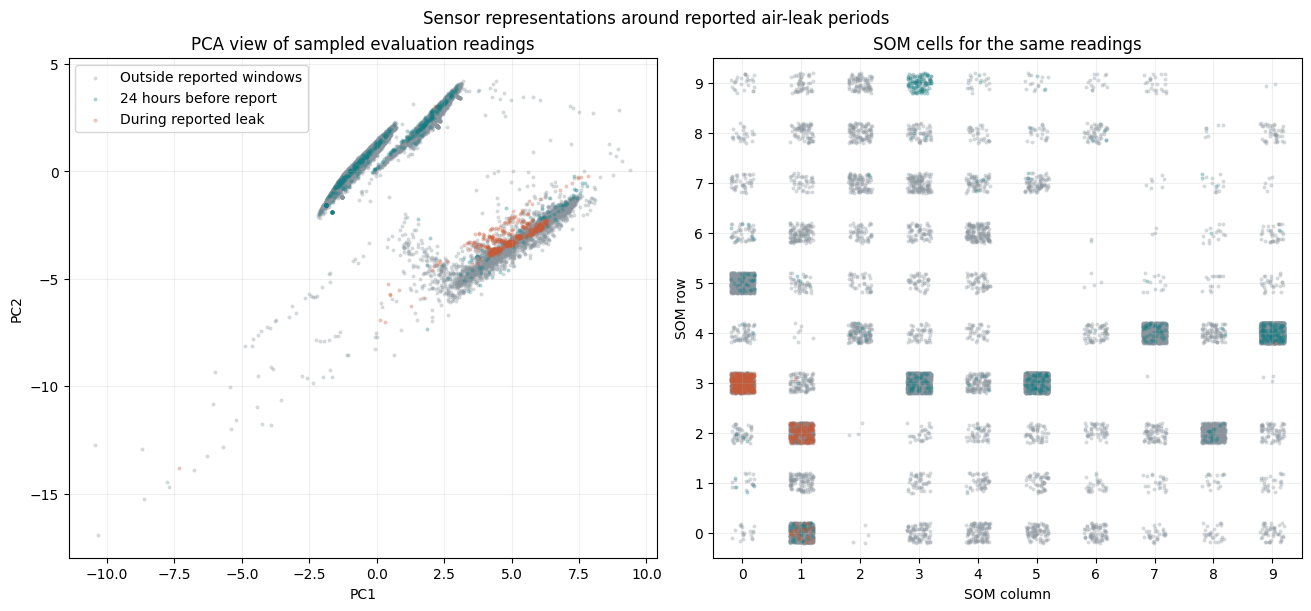

In [17]:
# Cell 16 — Compare PCA and SOM around reported air-leak periods

reported_leak_windows = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00")
]

sample_timestamps = evaluation_rows.index[som_sample_positions]

reading_period = np.full(
    len(sample_timestamps),
    "Outside reported windows",
    dtype=object
)

for start_text, end_text in reported_leak_windows:
    leak_start = pd.Timestamp(start_text)
    leak_end = pd.Timestamp(end_text)

    before_leak = (
        (sample_timestamps >= leak_start - pd.Timedelta(hours=24))
        & (sample_timestamps < leak_start)
    )

    during_leak = (
        (sample_timestamps >= leak_start)
        & (sample_timestamps < leak_end + pd.Timedelta(minutes=1))
    )

    reading_period[before_leak] = "24 hours before report"
    reading_period[during_leak] = "During reported leak"

period_order = [
    "Outside reported windows",
    "24 hours before report",
    "During reported leak"
]

period_summary = pd.DataFrame({
    "Period": period_order,
    "Sampled readings": [
        int(np.sum(reading_period == period))
        for period in period_order
    ]
})

display(period_summary)

som_period_table = pd.DataFrame({
    "Period": reading_period,
    "SOM X": som_assignments[:, 0],
    "SOM Y": som_assignments[:, 1]
})

cell_counts = (
    som_period_table
    .groupby(["Period", "SOM X", "SOM Y"])
    .size()
    .rename("Readings in cell")
    .reset_index()
)

top_cells = (
    cell_counts
    .sort_values("Readings in cell", ascending=False)
    .drop_duplicates("Period")
    .copy()
)

period_totals = period_summary.set_index("Period")["Sampled readings"]
top_cells["Total readings in period"] = top_cells["Period"].map(period_totals)
top_cells["Share of period (%)"] = (
    100 * top_cells["Readings in cell"]
    / top_cells["Total readings in period"]
).round(2)

print("Most-used SOM cell for each period")
display(top_cells.set_index("Period"))

category_colours = {
    "Outside reported windows": "#89949C",
    "24 hours before report": "#147D83",
    "During reported leak": "#C75B39"
}

pca_sample_for_events = evaluation_projection[som_sample_positions]

jitter = np.random.default_rng(41).uniform(
    -0.2, 0.2, size=som_assignments.shape
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    layout="constrained"
)

for period in period_order:
    selected = reading_period == period
    colour = category_colours[period]

    if selected.any():
        axes[0].scatter(
            pca_sample_for_events[selected, 0],
            pca_sample_for_events[selected, 1],
            color=colour,
            s=8,
            alpha=0.35,
            linewidths=0,
            label=period
        )

        axes[1].scatter(
            som_assignments[selected, 0] + jitter[selected, 0],
            som_assignments[selected, 1] + jitter[selected, 1],
            color=colour,
            s=8,
            alpha=0.35,
            linewidths=0,
            label=period
        )

axes[0].set_title("PCA view of sampled evaluation readings")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].grid(alpha=0.2)

axes[1].set_title("SOM cells for the same readings")
axes[1].set_xlabel("SOM column")
axes[1].set_ylabel("SOM row")
axes[1].set_xticks(range(som_grid_size))
axes[1].set_yticks(range(som_grid_size))
axes[1].set_xlim(-0.5, som_grid_size - 0.5)
axes[1].set_ylim(-0.5, som_grid_size - 0.5)
axes[1].grid(alpha=0.2)

axes[0].legend()
fig.suptitle("Sensor representations around reported air-leak periods")
plt.show()

## Check how specific the most-used leak-period SOM cell is

Find the SOM cell receiving the most readings during reported leaks. Compare its readings across leak, pre-report and outside-report periods, then compare the leak share in that cell with the overall sample.

In [18]:
# Cell 17 — Check the most-used leak-period cell against other periods

during_counts = (
    som_period_table.loc[
        som_period_table["Period"] == "During reported leak"
    ]
    .groupby(["SOM X", "SOM Y"])
    .size()
    .sort_values(ascending=False)
)

event_cell = tuple(during_counts.index[0])

cell_period_counts = pd.crosstab(
    index=[
        som_period_table["SOM X"],
        som_period_table["SOM Y"]
    ],
    columns=som_period_table["Period"]
)

counts_in_event_cell = cell_period_counts.loc[event_cell]
period_totals = som_period_table["Period"].value_counts()

event_cell_summary = pd.DataFrame({
    "Readings in this cell": counts_in_event_cell,
    "Share of period in this cell (%)": (
        counts_in_event_cell / period_totals * 100
    )
})

event_cell_summary = (
    event_cell_summary
    .reindex(period_order)
    .fillna(0)
)

total_in_event_cell = int(counts_in_event_cell.sum())

leak_share_in_cell = (
    counts_in_event_cell.get("During reported leak", 0)
    / total_in_event_cell
)

overall_leak_share = (
    period_totals.get("During reported leak", 0)
    / len(som_period_table)
)

print("Most-used leak-period SOM cell:", event_cell)
print(f"Leak readings as a share of this cell: {leak_share_in_cell:.2%}")
print(f"Leak readings as a share of the whole sample: {overall_leak_share:.2%}")

display(event_cell_summary.round(2))

Most-used leak-period SOM cell: (np.int64(0), np.int64(3))
Leak readings as a share of this cell: 38.10%
Leak readings as a share of the whole sample: 2.78%


,Readings in this cell,Share of period in this cell (%)
Period,,
Outside reported windows,520,2.76
24 hours before report,13,2.26
During reported leak,328,58.99


## Part A: Interpretation of the representations

PCA reduced the 13 sensor inputs to two components, which retained **71.00%** of the training data variation. The linear autoencoder's aligned evaluation coordinates were strongly related to the PCA coordinates: the correlations were **0.9990 for PC1** and **0.9442 for PC2**. On the validation readings, PCA had a lower reconstruction MSE (**0.81302**) than the autoencoder (**0.87134**).

The SOM grouped many sampled readings into a smaller number of map cells. The cell used most often during reported leak periods was **(0, 3)**. It contained **328 of the 556 sampled readings during reports (58.99%)**. Those leak-period readings made up **38.10%** of all sampled readings assigned to that cell, compared with **2.78%** leak-period readings in the full sample.

Only **2.26%** of readings from the 24 hours before a report were assigned to this cell. This analysis therefore shows an association between the SOM cell and readings during reported leaks, but it does not provide clear evidence that the representation identifies leaks in advance. Readings outside the selected report windows are not confirmed healthy readings, and the analysis uses four reported leak intervals.

# Part B — Aircraft Engine Remaining Useful Life Prediction

This part uses the NASA C-MAPSS turbofan engine dataset. The goal is to train a recurrent neural network to estimate an aircraft engine's remaining useful life (RUL) from its sensor history.

The data will be split by engine, and the model's estimates will be compared with simpler baseline methods.

In [28]:
# Upload and inspect the NASA C-MAPSS dataset ZIP

from pathlib import Path
from zipfile import ZipFile

from google.colab import files

uploaded_files = files.upload()

zip_files = [
    name for name in uploaded_files
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the NASA C-MAPSS dataset as a ZIP file.")

nasa_zip_path = Path(zip_files[0])

with ZipFile(nasa_zip_path) as archive:
    archive_contents = archive.namelist()

    print("Uploaded ZIP:", nasa_zip_path.name)
    print("Files inside the ZIP:")
    for file_name in archive_contents[:20]:
        print(" -", file_name)

    if len(archive_contents) > 20:
        print(f"... and {len(archive_contents) - 20} more files")

Saving 6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip to 6.+Turbofan+Engine+Degradation+Simulation+Data+Set (1).zip
Uploaded ZIP: 6.+Turbofan+Engine+Degradation+Simulation+Data+Set (1).zip
Files inside the ZIP:
 - 6. Turbofan Engine Degradation Simulation Data Set/
 - 6. Turbofan Engine Degradation Simulation Data Set/CMAPSSData.zip


## Load the FD001 engine data

The uploaded ZIP contains a second ZIP named `CMAPSSData.zip`. Read the FD001 training file, test file and RUL targets from that archive. Each sensor row includes an engine ID, an operating cycle, three operating settings and 21 sensor measurements.

In [29]:
# Cell 20 — Read FD001 files from the nested ZIP archive

from io import BytesIO
from zipfile import ZipFile

import pandas as pd
from IPython.display import display

setting_columns = [f"setting_{number}" for number in range(1, 4)]
sensor_columns = [f"sensor_{number:02d}" for number in range(1, 22)]

engine_columns = [
    "engine_id",
    "cycle",
    *setting_columns,
    *sensor_columns
]

with ZipFile(nasa_zip_path) as outer_archive:
    nested_archives = [
        name for name in outer_archive.namelist()
        if Path(name).name.lower() == "cmapssdata.zip"
    ]

    if len(nested_archives) != 1:
        raise ValueError(
            f"Expected one CMAPSSData.zip; found {len(nested_archives)}."
        )

    nested_bytes = BytesIO(outer_archive.read(nested_archives[0]))

    with ZipFile(nested_bytes) as data_archive:
        archive_members = {
            Path(name).name.lower(): name
            for name in data_archive.namelist()
        }

        required_members = [
            "train_fd001.txt",
            "test_fd001.txt",
            "rul_fd001.txt"
        ]

        missing_members = [
            name for name in required_members
            if name not in archive_members
        ]

        if missing_members:
            raise FileNotFoundError(
                f"Missing FD001 files: {missing_members}"
            )

        train_data = pd.read_csv(
            BytesIO(data_archive.read(archive_members["train_fd001.txt"])),
            sep=r"\s+",
            header=None
        )

        test_data = pd.read_csv(
            BytesIO(data_archive.read(archive_members["test_fd001.txt"])),
            sep=r"\s+",
            header=None
        )

        rul_targets = pd.read_csv(
            BytesIO(data_archive.read(archive_members["rul_fd001.txt"])),
            sep=r"\s+",
            header=None,
            names=["RUL"]
        )

if train_data.shape[1] != len(engine_columns):
    raise ValueError(
        f"Training file has {train_data.shape[1]} columns; "
        f"expected {len(engine_columns)}."
    )

if test_data.shape[1] != len(engine_columns):
    raise ValueError(
        f"Test file has {test_data.shape[1]} columns; "
        f"expected {len(engine_columns)}."
    )

train_data.columns = engine_columns
test_data.columns = engine_columns

print("Training data shape:", train_data.shape)
print("Training engines:", train_data["engine_id"].nunique())
print("Test data shape:", test_data.shape)
print("Test engines:", test_data["engine_id"].nunique())
print("Test RUL targets:", len(rul_targets))
display(train_data.head())

Training data shape: (20631, 26)
Training engines: 100
Test data shape: (13096, 26)
Test engines: 100
Test RUL targets: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Check the engine data and create training targets

Check the FD001 files for missing values, invalid numbers, duplicate engine-cycle records and gaps in cycle numbers. Create a remaining useful life (RUL) target for each training cycle, then split by engine to keep each engine entirely in one group.

In [30]:
# Cell 21 — Validate FD001 and create an engine-based validation split

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

train_data = train_data.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)

test_data = test_data.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)


def check_engine_file(frame, file_label):
    grouped = frame.groupby("engine_id")
    cycle_steps = grouped["cycle"].diff().dropna()
    numeric_values = frame.select_dtypes(include=[np.number]).to_numpy()

    return {
        "File": file_label,
        "Rows": len(frame),
        "Engines": frame["engine_id"].nunique(),
        "Missing values": int(frame.isna().sum().sum()),
        "Non-finite values": int((~np.isfinite(numeric_values)).sum()),
        "Duplicate engine-cycle pairs": int(
            frame.duplicated(["engine_id", "cycle"]).sum()
        ),
        "Engines starting at cycle 1": int(
            grouped["cycle"].min().eq(1).sum()
        ),
        "Cycle steps not equal to 1": int(cycle_steps.ne(1).sum())
    }


quality_table = pd.DataFrame([
    check_engine_file(train_data, "Training file"),
    check_engine_file(test_data, "Test file")
]).set_index("File")

display(quality_table)

problem_checks = [
    "Missing values",
    "Non-finite values",
    "Duplicate engine-cycle pairs",
    "Cycle steps not equal to 1"
]

if quality_table[problem_checks].to_numpy().any():
    raise ValueError("Review the data-quality checks before continuing.")

if quality_table["Engines starting at cycle 1"].ne(
    quality_table["Engines"]
).any():
    raise ValueError("Some engines do not begin at cycle 1.")

test_engine_ids = np.sort(test_data["engine_id"].unique())

if len(rul_targets) != len(test_engine_ids):
    raise ValueError("The number of test RUL targets does not match the engines.")

if not np.isfinite(rul_targets["RUL"]).all() or (
    rul_targets["RUL"] < 0
).any():
    raise ValueError("The test RUL targets contain invalid values.")

test_rul_by_engine = pd.Series(
    rul_targets["RUL"].to_numpy(),
    index=test_engine_ids,
    name="RUL"
)

# For each training cycle, RUL equals the engine's last cycle minus this cycle.
train_data["RUL"] = (
    train_data.groupby("engine_id")["cycle"].transform("max")
    - train_data["cycle"]
)

# Keep all cycles from each engine together during the split.
engine_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=29
)

train_indices, validation_indices = next(
    engine_splitter.split(
        train_data,
        groups=train_data["engine_id"]
    )
)

cm_train = train_data.iloc[train_indices].copy()
cm_validation = train_data.iloc[validation_indices].copy()
cm_test = test_data.copy()

split_table = pd.DataFrame([
    {
        "Split": split_name,
        "Engines": frame["engine_id"].nunique(),
        "Cycle rows": len(frame)
    }
    for split_name, frame in [
        ("Model training", cm_train),
        ("Validation", cm_validation),
        ("Official test", cm_test)
    ]
]).set_index("Split")

display(split_table)
print("Official test RUL targets:", len(test_rul_by_engine))
display(cm_train[["engine_id", "cycle", "RUL"]].head())

,Rows,Engines,Missing values,Non-finite values,Duplicate engine-cycle pairs,Engines starting at cycle 1,Cycle steps not equal to 1
File,,,,,,,
Training file,20631,100,0,0,0,100,0
Test file,13096,100,0,0,0,100,0


,Engines,Cycle rows
Split,,
Model training,80,16774
Validation,20,3857
Official test,100,13096


Official test RUL targets: 100


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


## Select and scale the engine inputs

Use cycle number, operating settings and sensor readings as model inputs. Remove features that are constant in the training split. Fit the scaler on training engines only and apply it to the validation and official test data.

In [31]:
# Cell 22 — Select varying features and scale them using training engines

from sklearn.preprocessing import StandardScaler

candidate_features = [
    "cycle",
    *setting_columns,
    *sensor_columns
]

feature_variation = cm_train[candidate_features].nunique()

model_features = feature_variation[
    feature_variation > 1
].index.tolist()

constant_features = feature_variation[
    feature_variation <= 1
].index.tolist()

input_scaler = StandardScaler()
input_scaler.fit(cm_train[model_features])

scaled_feature_names = [
    "cycle_scaled" if name == "cycle" else name
    for name in model_features
]


def scale_engine_rows(frame):
    scaled_array = input_scaler.transform(
        frame[model_features]
    ).astype("float32")

    scaled_inputs = pd.DataFrame(
        scaled_array,
        index=frame.index,
        columns=scaled_feature_names
    )

    metadata_columns = ["engine_id", "cycle"]

    if "RUL" in frame.columns:
        metadata_columns.append("RUL")

    return pd.concat(
        [frame[metadata_columns].copy(), scaled_inputs],
        axis=1
    )


cm_train_scaled = scale_engine_rows(cm_train)
cm_validation_scaled = scale_engine_rows(cm_validation)
cm_test_scaled = scale_engine_rows(cm_test)

print(f"Model input features retained: {len(model_features)}")
print("Constant features removed:", constant_features)
print("Scaled input columns:", scaled_feature_names)
print("Scaled training shape:", cm_train_scaled.shape)
print("Scaled validation shape:", cm_validation_scaled.shape)
print("Scaled official test shape:", cm_test_scaled.shape)

display(cm_train_scaled.head())

Model input features retained: 18
Constant features removed: ['setting_3', 'sensor_01', 'sensor_05', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Scaled input columns: ['cycle_scaled', 'setting_1', 'setting_2', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_06', 'sensor_07', 'sensor_08', 'sensor_09', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Scaled training shape: (16774, 21)
Scaled validation shape: (3857, 21)
Scaled official test shape: (13096, 20)


,engine_id,cycle,RUL,cycle_scaled,setting_1,setting_2,sensor_02,sensor_03,sensor_04,sensor_06,...,sensor_08,sensor_09,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,191,-1.559434,-0.318245,-1.367936,-1.694265,-0.120171,-0.901559,0.143404,...,-0.489382,-0.892085,-0.246488,0.313114,-1.031408,-0.289509,-0.585189,-0.762948,1.322042,1.170610
1,1,2,190,-1.545234,0.869635,-1.026186,-1.038853,0.222602,-0.621776,0.143404,...,-0.769281,-0.989946,-0.172338,1.145232,-0.339712,-0.670692,-0.259498,-0.762948,0.992987,1.212795
2,1,3,189,-1.531034,-1.963003,1.024312,-0.641633,-0.396653,-0.505017,0.143404,...,-0.209482,-0.580496,-0.987984,1.333130,-0.893069,-0.577669,-0.630203,-2.044512,0.718773,0.484650
3,1,4,188,-1.516834,0.321383,-0.000937,-0.641633,-1.237417,-0.761668,0.143404,...,0.210367,-0.740214,-1.507032,1.923665,-0.201373,-0.545591,-1.943558,-0.762948,0.334875,0.757016
4,1,5,187,-1.502634,-0.866498,-0.684436,-0.601911,-1.227716,-0.282512,0.143404,...,-0.489382,-0.478479,-0.950910,1.024441,-0.754730,-0.547195,-0.323047,-0.122166,0.444560,1.036719


## Build engine sensor sequences

Create 30-cycle input windows for the LSTM. Use sliding windows from the training engines, several checkpoints from each validation engine, and the final available window from each official test engine.

In [32]:
# Cell 23 — Create fixed-length sequences for the LSTM

window_length = 30


def build_engine_windows(frame, window_size, split_kind):
    sequences = []
    rul_values = []
    engine_ids = []
    end_cycles = []

    for engine_id, engine_rows in frame.groupby("engine_id", sort=True):
        engine_rows = engine_rows.sort_values("cycle")

        sensor_history = engine_rows[
            scaled_feature_names
        ].to_numpy(dtype=np.float32)

        row_count = len(sensor_history)

        if row_count < window_size:
            raise ValueError(
                f"Engine {engine_id} has only {row_count} cycles; "
                f"{window_size} are required."
            )

        if split_kind == "training":
            window_ends = range(window_size, row_count + 1)

        elif split_kind == "validation":
            checkpoints = [
                int(row_count * fraction)
                for fraction in (0.40, 0.60, 0.80)
            ]
            window_ends = sorted({
                max(window_size, checkpoint)
                for checkpoint in checkpoints
            })

        elif split_kind == "official_test":
            window_ends = [row_count]

        else:
            raise ValueError(f"Unknown split type: {split_kind}")

        for end_position in window_ends:
            sequences.append(
                sensor_history[end_position - window_size:end_position]
            )
            engine_ids.append(engine_id)
            end_cycles.append(
                int(engine_rows["cycle"].iloc[end_position - 1])
            )

            if split_kind != "official_test":
                rul_values.append(
                    float(engine_rows["RUL"].iloc[end_position - 1])
                )

    sequence_array = np.stack(sequences).astype(np.float32)
    target_array = np.asarray(rul_values, dtype=np.float32)

    return (
        sequence_array,
        target_array,
        np.asarray(engine_ids),
        np.asarray(end_cycles)
    )


cm_X_train, cm_y_train, cm_train_ids, cm_train_end_cycles = (
    build_engine_windows(
        cm_train_scaled,
        window_length,
        "training"
    )
)

cm_X_validation, cm_y_validation, cm_validation_ids, cm_validation_end_cycles = (
    build_engine_windows(
        cm_validation_scaled,
        window_length,
        "validation"
    )
)

cm_X_test, _, cm_test_ids, cm_test_end_cycles = build_engine_windows(
    cm_test_scaled,
    window_length,
    "official_test"
)

print("Training sequence shape:", cm_X_train.shape)
print("Training RUL target shape:", cm_y_train.shape)
print("Validation sequence shape:", cm_X_validation.shape)
print("Validation RUL target shape:", cm_y_validation.shape)
print("Official test sequence shape:", cm_X_test.shape)
print("Official test engines:", len(np.unique(cm_test_ids)))

Training sequence shape: (14454, 30, 18)
Training RUL target shape: (14454,)
Validation sequence shape: (60, 30, 18)
Validation RUL target shape: (60,)
Official test sequence shape: (100, 30, 18)
Official test engines: 100


## Configure the LSTM model

Build a two-layer LSTM that reads each 30-cycle sensor window and outputs one RUL estimate. Standardise the training RUL targets for model fitting; convert predictions back to cycles during evaluation.

In [33]:
# Cell 24 — Prepare target scaling, batches and LSTM architecture

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(29)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

rul_mean = float(cm_y_train.mean())
rul_std = float(cm_y_train.std())

if rul_std == 0:
    raise ValueError("Training RUL targets have zero standard deviation.")

cm_y_train_scaled = (
    (cm_y_train - rul_mean) / rul_std
).astype(np.float32)

train_tensor_dataset = TensorDataset(
    torch.from_numpy(cm_X_train),
    torch.from_numpy(cm_y_train_scaled)
)

train_batches = DataLoader(
    train_tensor_dataset,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(29)
)


class EngineLifeLSTM(nn.Module):
    def __init__(self, input_features):
        super().__init__()

        self.sequence_model = nn.LSTM(
            input_size=input_features,
            hidden_size=48,
            num_layers=2,
            batch_first=True,
            dropout=0.20
        )

        self.output_layer = nn.Sequential(
            nn.LayerNorm(48),
            nn.Linear(48, 24),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Linear(24, 1)
        )

    def forward(self, sequence):
        _, (hidden_state, _) = self.sequence_model(sequence)
        final_state = hidden_state[-1]
        return self.output_layer(final_state).squeeze(-1)


lstm_model = EngineLifeLSTM(
    input_features=cm_X_train.shape[2]
).to(device)

optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=0.001
)

training_loss_function = nn.SmoothL1Loss()

print(lstm_model)
print(f"RUL target mean: {rul_mean:.2f} cycles")
print(f"RUL target standard deviation: {rul_std:.2f} cycles")

Training device: cpu
EngineLifeLSTM(
  (sequence_model): LSTM(18, 48, num_layers=2, batch_first=True, dropout=0.2)
  (output_layer): Sequential(
    (0): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=48, out_features=24, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=24, out_features=1, bias=True)
  )
)
RUL target mean: 96.20 cycles
RUL target standard deviation: 63.51 cycles


## Train and validate the LSTM

Train the LSTM on the training-engine windows. After each epoch, calculate validation MAE in cycles and retain the model with the lowest validation error. Stop early if validation performance stops improving.

In [34]:
# Cell 25 — Train the LSTM and select the best validation model

import copy

def predict_rul(model, sequences, batch_size=512):
    model.eval()
    predictions = []

    with torch.inference_mode():
        for start in range(0, len(sequences), batch_size):
            batch = torch.from_numpy(
                sequences[start:start + batch_size]
            ).to(device)

            scaled_predictions = model(batch)
            cycle_predictions = scaled_predictions * rul_std + rul_mean

            predictions.append(cycle_predictions.cpu().numpy())

    return np.clip(
        np.concatenate(predictions),
        a_min=0,
        a_max=None
    )


training_log = []
best_validation_mae = float("inf")
best_model_weights = None
best_epoch = 0
epochs_without_improvement = 0

maximum_epochs = 30
early_stop_rounds = 5

for epoch in range(1, maximum_epochs + 1):
    lstm_model.train()
    accumulated_loss = 0.0

    for sequences, scaled_targets in train_batches:
        sequences = sequences.to(device)
        scaled_targets = scaled_targets.to(device)

        optimizer.zero_grad()
        predicted_targets = lstm_model(sequences)
        loss = training_loss_function(predicted_targets, scaled_targets)
        loss.backward()

        nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        accumulated_loss += loss.item() * len(sequences)

    average_training_loss = accumulated_loss / len(train_tensor_dataset)

    validation_predictions = predict_rul(
        lstm_model,
        cm_X_validation
    )

    validation_mae = float(
        np.mean(np.abs(validation_predictions - cm_y_validation))
    )

    training_log.append({
        "Epoch": epoch,
        "Training loss": average_training_loss,
        "Validation MAE (cycles)": validation_mae
    })

    if validation_mae < best_validation_mae:
        best_validation_mae = validation_mae
        best_model_weights = copy.deepcopy(lstm_model.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Training loss: {average_training_loss:.4f} | "
        f"Validation MAE: {validation_mae:.2f} cycles"
    )

    if epochs_without_improvement >= early_stop_rounds:
        print("Early stopping: validation MAE did not improve.")
        break

lstm_model.load_state_dict(best_model_weights)
lstm_model.eval()

print("Selected epoch:", best_epoch)
print(f"Best validation MAE: {best_validation_mae:.2f} cycles")

Epoch 01 | Training loss: 0.1697 | Validation MAE: 23.88 cycles
Epoch 02 | Training loss: 0.1418 | Validation MAE: 23.65 cycles
Epoch 03 | Training loss: 0.1311 | Validation MAE: 23.28 cycles
Epoch 04 | Training loss: 0.1138 | Validation MAE: 30.18 cycles
Epoch 05 | Training loss: 0.0945 | Validation MAE: 28.38 cycles
Epoch 06 | Training loss: 0.0773 | Validation MAE: 32.06 cycles
Epoch 07 | Training loss: 0.0633 | Validation MAE: 33.51 cycles
Epoch 08 | Training loss: 0.0514 | Validation MAE: 30.93 cycles
Early stopping: validation MAE did not improve.
Selected epoch: 3
Best validation MAE: 23.28 cycles


## Evaluate the LSTM on the official test engines

Generate one RUL estimate for each official test engine. Compare the LSTM against a training-median baseline and a Ridge model using the latest cycle in each input window.

In [35]:
# Cell 26 — Compare official-test predictions with two baselines

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

lstm_test_predictions = predict_rul(
    lstm_model,
    cm_X_test
)

actual_test_rul = test_rul_by_engine.loc[
    cm_test_ids
].to_numpy(dtype=np.float32)

median_baseline_predictions = np.full(
    len(actual_test_rul),
    np.median(cm_y_train),
    dtype=np.float32
)

ridge_model = Ridge(alpha=10.0)
ridge_model.fit(
    cm_X_train[:, -1, :],
    cm_y_train
)

ridge_test_predictions = np.clip(
    ridge_model.predict(cm_X_test[:, -1, :]),
    a_min=0,
    a_max=None
)

test_predictions = pd.DataFrame({
    "engine_id": cm_test_ids,
    "Actual RUL": actual_test_rul,
    "LSTM prediction": lstm_test_predictions,
    "Ridge prediction": ridge_test_predictions,
    "Training median prediction": median_baseline_predictions
}).set_index("engine_id")


def calculate_rul_metrics(actual, predicted):
    prediction_error = predicted - actual

    return {
        "MAE (cycles)": mean_absolute_error(actual, predicted),
        "RMSE (cycles)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean error (cycles)": prediction_error.mean()
    }


prediction_methods = [
    "Training median prediction",
    "Ridge prediction",
    "LSTM prediction"
]

test_metric_table = pd.DataFrame({
    method: calculate_rul_metrics(
        test_predictions["Actual RUL"],
        test_predictions[method]
    )
    for method in prediction_methods
}).T

print("Official test performance")
display(test_metric_table.round(2))

print("Example engine predictions")
display(test_predictions.head(10).round(2))

Official test performance


,MAE (cycles),RMSE (cycles),Mean error (cycles)
Training median prediction,35.98,44.01,14.48
Ridge prediction,22.94,28.20,15.18
LSTM prediction,20.39,26.85,10.67


Example engine predictions


,Actual RUL,LSTM prediction,Ridge prediction,Training median prediction
engine_id,,,,
1,112.0,138.399994,160.710007,90.0
2,98.0,164.089996,126.839996,90.0
3,69.0,69.790001,83.779999,90.0
4,82.0,87.010002,97.220001,90.0
5,91.0,111.839996,109.730003,90.0
6,93.0,104.500000,109.370003,90.0
7,91.0,128.559998,110.629997,90.0
8,95.0,63.209999,78.410004,90.0
9,111.0,166.279999,121.790001,90.0


## Inspect official-test predictions

Compare the LSTM and Ridge estimates with the official RUL values. Also examine performance on engines with 30 or fewer actual cycles remaining.

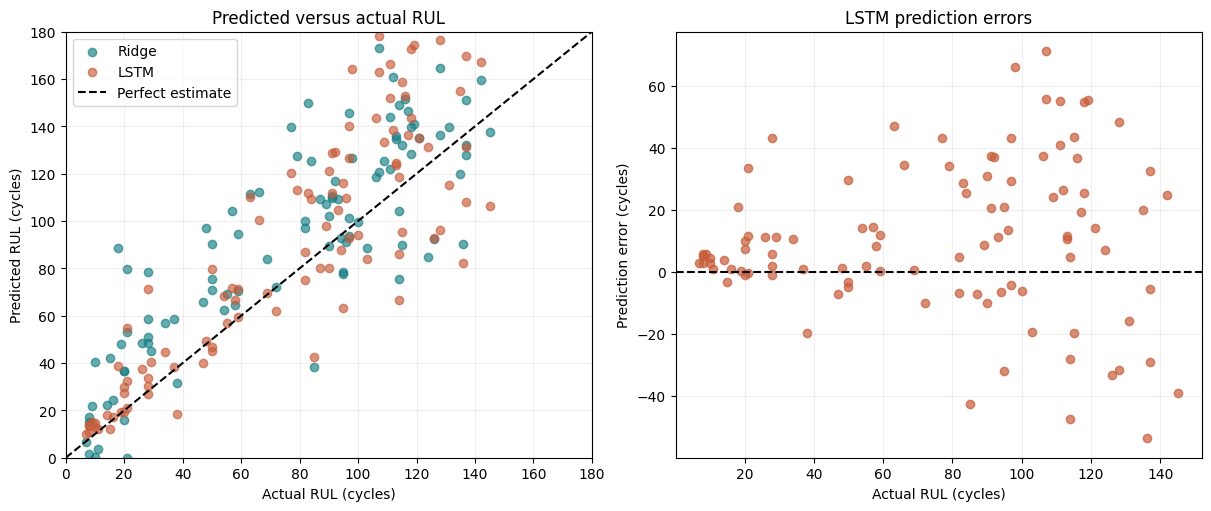

Test engines with actual RUL of 30 cycles or less: 25


,MAE (cycles),Overestimated RUL cases
Method,,
Ridge prediction,21.57,19
LSTM prediction,7.99,21


In [36]:
# Cell 27 — Plot test predictions and inspect near-failure engines

actual_rul = test_predictions["Actual RUL"].to_numpy()
lstm_rul = test_predictions["LSTM prediction"].to_numpy()
ridge_rul = test_predictions["Ridge prediction"].to_numpy()

axis_limit = np.ceil(
    max(actual_rul.max(), lstm_rul.max(), ridge_rul.max()) / 10
) * 10

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    layout="constrained"
)

axes[0].scatter(
    actual_rul,
    ridge_rul,
    color="#147D83",
    alpha=0.65,
    label="Ridge"
)
axes[0].scatter(
    actual_rul,
    lstm_rul,
    color="#C75B39",
    alpha=0.65,
    label="LSTM"
)
axes[0].plot(
    [0, axis_limit],
    [0, axis_limit],
    linestyle="--",
    color="black",
    label="Perfect estimate"
)
axes[0].set(
    title="Predicted versus actual RUL",
    xlabel="Actual RUL (cycles)",
    ylabel="Predicted RUL (cycles)",
    xlim=(0, axis_limit),
    ylim=(0, axis_limit)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

lstm_errors = lstm_rul - actual_rul

axes[1].scatter(
    actual_rul,
    lstm_errors,
    color="#C75B39",
    alpha=0.7
)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(
    title="LSTM prediction errors",
    xlabel="Actual RUL (cycles)",
    ylabel="Prediction error (cycles)"
)
axes[1].grid(alpha=0.2)

plt.show()

near_failure = test_predictions.loc[
    test_predictions["Actual RUL"] <= 30
]

print("Test engines with actual RUL of 30 cycles or less:", len(near_failure))

if len(near_failure) > 0:
    near_failure_results = []

    for method in ["Ridge prediction", "LSTM prediction"]:
        errors = (
            near_failure[method].to_numpy()
            - near_failure["Actual RUL"].to_numpy()
        )

        near_failure_results.append({
            "Method": method,
            "MAE (cycles)": np.mean(np.abs(errors)),
            "Overestimated RUL cases": int((errors > 0).sum())
        })

    display(
        pd.DataFrame(near_failure_results)
        .set_index("Method")
        .round(2)
    )

## Examine RUL estimates at different points in engine life

The validation set contains three checkpoints for each engine. Compare actual and predicted RUL at these checkpoints, and inspect three validation engines with shorter, median and longer lifetimes.

Validation MAE by observation point


,MAE (cycles)
Life observed (%),
39,25.820000
40,33.360001
59,68.070000
60,20.059999
80,14.410000


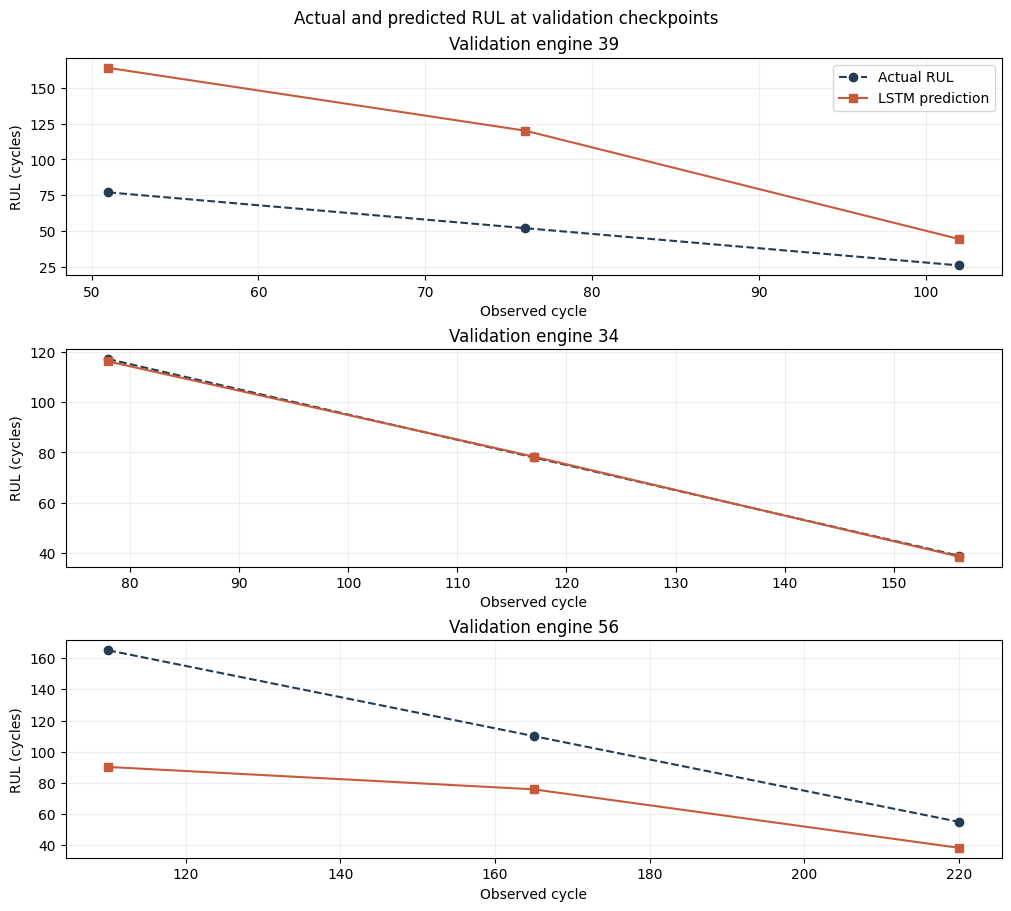

In [37]:
# Cell 28 — Examine validation predictions across engine life

validation_lstm_predictions = predict_rul(
    lstm_model,
    cm_X_validation
)

validation_temporal_results = pd.DataFrame({
    "engine_id": cm_validation_ids,
    "Observed cycle": cm_validation_end_cycles,
    "Actual RUL": cm_y_validation,
    "Predicted RUL": validation_lstm_predictions
})

validation_lifetimes = (
    cm_validation.groupby("engine_id")["cycle"]
    .max()
)

validation_temporal_results["Engine lifetime"] = (
    validation_temporal_results["engine_id"]
    .map(validation_lifetimes)
)

validation_temporal_results["Life observed (%)"] = (
    100
    * validation_temporal_results["Observed cycle"]
    / validation_temporal_results["Engine lifetime"]
).round(0).astype(int)

validation_temporal_results["Absolute error"] = np.abs(
    validation_temporal_results["Predicted RUL"]
    - validation_temporal_results["Actual RUL"]
)

print("Validation MAE by observation point")
display(
    validation_temporal_results
    .groupby("Life observed (%)")["Absolute error"]
    .mean()
    .rename("MAE (cycles)")
    .round(2)
    .to_frame()
)

sorted_lifetimes = validation_lifetimes.sort_values()
rank_positions = [
    0,
    len(sorted_lifetimes) // 2,
    len(sorted_lifetimes) - 1
]
example_engine_ids = [
    int(sorted_lifetimes.index[position])
    for position in rank_positions
]

fig, axes = plt.subplots(
    len(example_engine_ids),
    1,
    figsize=(10, 9),
    layout="constrained"
)

for axis, engine_id in zip(axes, example_engine_ids):
    engine_results = (
        validation_temporal_results.loc[
            validation_temporal_results["engine_id"] == engine_id
        ]
        .sort_values("Observed cycle")
    )

    axis.plot(
        engine_results["Observed cycle"],
        engine_results["Actual RUL"],
        marker="o",
        linestyle="--",
        color="#243B53",
        label="Actual RUL"
    )

    axis.plot(
        engine_results["Observed cycle"],
        engine_results["Predicted RUL"],
        marker="s",
        color="#C75B39",
        label="LSTM prediction"
    )

    axis.set_title(f"Validation engine {engine_id}")
    axis.set_xlabel("Observed cycle")
    axis.set_ylabel("RUL (cycles)")
    axis.grid(alpha=0.2)

axes[0].legend()
fig.suptitle("Actual and predicted RUL at validation checkpoints")
plt.show()

In [38]:
# Correct the checkpoint labels and recompute validation MAE

validation_temporal_results = validation_temporal_results.sort_values(
    ["engine_id", "Observed cycle"]
).copy()

checkpoint_number = (
    validation_temporal_results
    .groupby("engine_id")
    .cumcount()
)

validation_temporal_results["Checkpoint (%)"] = (
    checkpoint_number.map({
        0: 40,
        1: 60,
        2: 80
    })
)

if validation_temporal_results["Checkpoint (%)"].isna().any():
    raise ValueError("An engine does not have exactly three validation checkpoints.")

checkpoint_summary = (
    validation_temporal_results
    .groupby("Checkpoint (%)")
    .agg(
        Engines=("engine_id", "nunique"),
        Mean_actual_RUL=("Actual RUL", "mean"),
        Mean_predicted_RUL=("Predicted RUL", "mean"),
        MAE_cycles=("Absolute error", "mean")
    )
)

display(checkpoint_summary.round(2))

,Engines,Mean_actual_RUL,Mean_predicted_RUL,MAE_cycles
Checkpoint (%),,,,
40,20,115.949997,127.860001,32.980000
60,20,77.550003,92.309998,22.459999
80,20,38.900002,48.860001,14.410000


## Part B: Interpretation of LSTM results

On the official FD001 test set of 100 engines, the LSTM achieved an MAE of **20.39 cycles** and an RMSE of **26.85 cycles**. It performed better overall than the Ridge baseline (MAE **22.94**, RMSE **28.20**) and the training-median baseline (MAE **35.98**, RMSE **44.01**).

The LSTM's mean test error was **+10.67 cycles**, where error is prediction minus actual RUL. This indicates an average tendency to overestimate remaining life. For engines with 30 or fewer actual cycles remaining, the LSTM's MAE was **7.99 cycles**, compared with **21.57 cycles** for Ridge. However, the LSTM overestimated RUL for **21 of those 25 engines**, which is an important maintenance-risk limitation.

Across validation checkpoints, the LSTM's MAE decreased from **32.98 cycles at 40% of engine life**, to **22.46 at 60%**, and **14.41 at 80%**. This suggests that its estimates became more accurate as more of the engine's history was observed. The average prediction was still higher than the average actual RUL at each checkpoint. The example engine plots also show that accuracy varies between engines.

Overall, the LSTM captured the general decline in RUL for some engines and outperformed the two baselines on the full test set. Its tendency to overestimate RUL, especially near failure, means the estimates should be interpreted cautiously. These results apply to the simulated FD001 subset used in this assignment.